# Is a PSI Below 0.10 Enough? Statistically Justified Monitoring Thresholds, Adversarial Validation, Drift Detectors (ADWIN, DDM) and Leakage Checks on Ten Years of Mortgage Vintages

Credit models are monitored with a handful of rules of thumb, the best known being the population stability index: below 0.10 the population is "stable", above 0.25 the model needs attention. The rule ignores sample size, says nothing about whether the model still ranks or predicts well, and cannot see a deterioration that does not change the applicants' attributes. This notebook puts the standard monitoring toolkit through two real episodes: the 2006–2008 mortgage vintages, which defaulted at three to four times the rate of 2005 with applicants that looked much the same, and the 2019–2024 vintages, whose applicant mix swung with the 2020–2021 refinancing boom while their credit quality barely moved. It also answers the questions validators ask before monitoring starts: is anything leaking from the future, are the scorecard's bins stable, how uncertain are its parameters, and does it beat a simple benchmark?

**What it does.**

1. It reads loan-level origination data for Fannie Mae loans originated in 2005–2008 and Freddie Mac loans originated in 2018–2023, with a flag for default (90 days past due or a credit event, ignoring arrears accrued in COVID-19 forbearance) in the first 18 months.
2. It develops a weight-of-evidence logistic scorecard and a LightGBM challenger on one vintage per book (2005 and 2018), with FICO-only and three-variable benchmarks.
3. It monitors every later quarterly cohort: population stability of the score and each attribute against thresholds derived from the PSI's sampling distribution, discrimination with confidence intervals, calibration, and adversarial validation (how well a classifier can tell the cohort from the development sample).
4. It runs two streaming drift detectors, ADWIN and DDM, on the score as loans are originated and on outcomes as they become known 18 months later, and records when each would have raised an alarm.
5. It checks for target and temporal leakage, the stability of the weight-of-evidence bins across vintages, the bootstrap uncertainty of the scorecard's parameters, and the gain over simple benchmarks.

**Data.** Fannie Mae Single-Family Loan Performance Data and Freddie Mac Single-Family Loan-Level Dataset (samples, downloaded once by hand into `data/` at the repository root); the 30-year mortgage rate (FRED).

**Methods.** Weight-of-evidence binning with monotone merging, information value, logistic regression, LightGBM, the population and characteristic stability indices with chi-square thresholds, AUC with Hanley–McNeil standard errors, adversarial validation, ADWIN and DDM drift detectors, univariate leakage screens, random versus out-of-time cross-validation, and bootstrap parameter uncertainty.

**Key output.** For each cohort, the score PSI against the 0.10 rule and the statistical threshold, AUC with confidence intervals, observed versus predicted default rates and the adversarial AUC; the alarm dates of each detector; and the leakage, bin-stability, parameter-uncertainty and benchmark checks.

## 1. What monitoring is supposed to catch

A deployed PD model can go wrong in three ways:
- **Population shift:** the applicants change (a refinancing wave, a new channel, a credit-policy change). The model may still rank them well, or not.
- **Concept shift:** the link between attributes and default changes (house prices fall, so the same LTV becomes riskier). The applicants look the same, so population indices cannot see it.
- **Pipeline errors:** a variable is recoded or computed from information that is not available at origination.

**The population stability index.** For B score bins with development shares *pᵢ* and monitoring shares *qᵢ*,

PSI = Σ (*qᵢ* − *pᵢ*) ln(*qᵢ* / *pᵢ*).

The 0.10 and 0.25 thresholds come from industry practice (Siddiqi, 2017), not from statistics. Under no shift, with *n* development and *m* monitoring observations, PSI is approximately (1/*n* + 1/*m*) times a χ² variable with B − 1 degrees of freedom (Yurdakul & Naranjo, 2020). For samples of tens of thousands the 99% critical value is around 0.002, fifty times below 0.10; for a segment of a few hundred loans it is close to 0.10. A fixed threshold is therefore too lax for large portfolios and too strict for small ones, and neither tells whether the shift matters for the model's accuracy.

**Adversarial validation.** Train a classifier to distinguish the development sample from the new cohort. An AUC near 0.5 means the populations are indistinguishable; the features it relies on are the ones that moved.

**Streaming detectors.** DDM (Gama et al., 2004) tracks a Bernoulli error rate and signals when it exceeds its historical minimum by three standard deviations. ADWIN (Bifet & Gavaldà, 2007) keeps a window of recent observations and drops its older part whenever the means of the two parts differ by more than a bound that holds with confidence 1 − δ. In credit, outcomes arrive with a delay (here 18 months), which limits how fast any outcome-based detector can react.

**Leakage.** A feature leaks if it carries information that would not have been available when the decision was made (Kaufman et al., 2012). In credit data the usual culprits are fields updated after origination, such as modification flags or the number of months a loan was observed.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import zipfile

import lightgbm as lgb
from scipy.stats import chi2, norm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2018
rng = np.random.default_rng(SEED)
HORIZON = 18  # months after first payment
# last month of performance data in the samples
DATA_END = "2026-03"
BOOKS = {
    "Fannie Mae": ("fannie_mae", [2005, 2006, 2007, 2008], 2005),
    "Freddie Mac": ("freddie_mac", [2018, 2019, 2020, 2021, 2022, 2023], 2018),
}
N_BINS, N_BOOT = 10, 200
DELTA_ADWIN = 0.002

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-11-04


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Loans, outcomes and two leaky fields

Each loan is one observation at origination. The target is default within 18 months of the first payment: 90 days past due, or a short sale, third-party sale, note sale or REO. Arrears accrued while the loan was in a COVID-19 forbearance plan do not count. Loans whose 18-month window ends after the last month of data are dropped. The cohort is the quarter of origination.

Two fields are deliberately kept although they are only known after origination, to test the leakage checks: whether the loan was **ever modified**, and the **number of months it was reported** in the performance file (short for loans that prepaid or defaulted early).

In [3]:
OC = [
    "fico",
    "first_pay",
    "fthb",
    "maturity",
    "msa",
    "mi_pct",
    "units",
    "occupancy",
    "cltv",
    "dti",
    "upb",
    "ltv",
    "rate",
    "channel",
    "ppm",
    "amort",
    "state",
    "prop_type",
    "zip",
    "loan_id",
    "purpose",
    "term",
    "n_borrowers",
]
DEFAULT_ZB = {"02", "03", "09", "15"}


def find_shared(name):
    for d in [PROJECT_DIR, *PROJECT_DIR.parents]:
        if (d / "data" / name).exists():
            return d / "data" / name
    return None


def read_vintage(zp, year):
    with zipfile.ZipFile(zp) as z:
        o = pd.read_csv(
            z.open(f"sample_orig_{year}.txt"),
            sep="|",
            header=None,
            usecols=range(len(OC)),
            names=OC,
            dtype=str,
        )
        bad, seen, mod = [], [], []
        for ch in pd.read_csv(
            z.open(f"sample_perf_{year}.txt"),
            sep="|",
            header=None,
            usecols=[0, 3, 4, 7, 8, 29],
            names=["loan_id", "dlq", "age", "mod", "zb", "assist"],
            dtype=str,
            chunksize=3_000_000,
        ):
            age = pd.to_numeric(ch["age"], errors="coerce")
            dlq = pd.to_numeric(
                ch["dlq"].replace({"RA": "99"}), errors="coerce"
            )
            b = ((dlq >= 3) | ch["zb"].isin(DEFAULT_ZB)) & ch["assist"].ne("F")
            bad.append(
                pd.DataFrame({"loan_id": ch.loc[b, "loan_id"], "age": age[b]})
            )
            seen.append(
                pd.DataFrame({"loan_id": ch["loan_id"], "age": age})
                .groupby("loan_id")["age"]
                .max()
            )
            mod.append(ch.loc[ch["mod"].isin(["Y", "P"]), "loan_id"])
    first = pd.concat(bad).groupby("loan_id")["age"].min()
    o["default_age"] = o["loan_id"].map(first)
    o["months_reported"] = o["loan_id"].map(
        pd.concat(seen).groupby(level=0).max()
    )
    o["ever_modified"] = o["loan_id"].isin(set(pd.concat(mod))).astype(int)
    o["vintage"] = year
    return o


def load_all():
    out = []
    for book, (folder, years, _) in BOOKS.items():
        base = find_shared(folder)
        if base is None:
            continue
        for y in years:
            hits = [
                h
                for h in base.rglob(f"sample_{y}.zip")
                if "_to_delete" not in h.parts
            ]
            if hits:
                v = read_vintage(min(hits, key=lambda h: len(h.parts)), y)
                v["book"] = book
                out.append(v)
    return pd.concat(out, ignore_index=True)


L = cached("mortgage_origination_18m", load_all, max_age_hours=24 * 60)
for c in [
    "fico",
    "mi_pct",
    "units",
    "cltv",
    "dti",
    "upb",
    "ltv",
    "rate",
    "term",
    "n_borrowers",
    "default_age",
    "months_reported",
]:
    L[c] = pd.to_numeric(L[c], errors="coerce")
L["first_pay"] = pd.to_datetime(L["first_pay"], format="%Y%m")
L["orig_month"] = L["first_pay"] - pd.DateOffset(months=2)
L = L[
    (L["amort"] == "FRM")
    & L["term"].between(300, 360)
    & L["fico"].between(300, 850)
    & L["cltv"].between(1, 200)
    & L["rate"].between(1, 15)
    & (
        L["first_pay"] + pd.DateOffset(months=HORIZON)
        <= pd.Timestamp(DATA_END)
    )
].copy()
L["default"] = (L["default_age"] <= HORIZON).astype(int)
L["cohort"] = L["orig_month"].dt.to_period("Q").astype(str)
L["dti"] = L["dti"].where(L["dti"].between(1, 65))
L["mi_pct"] = L["mi_pct"].where(L["mi_pct"].between(0, 60), 0)

pmms = fred.get_series("MORTGAGE30US").resample("MS").mean()
L["sato"] = L["rate"] - pmms.reindex(L["orig_month"].values).to_numpy()
L["log_upb"] = np.log(L["upb"])
L["multi_borrower"] = (L["n_borrowers"] >= 2).astype(int)
L["multi_unit"] = (L["units"] >= 2).astype(int)
L = L.dropna(subset=["sato"]).reset_index(drop=True)
L.groupby(["book", "vintage"]).agg(
    loans=("default", "size"),
    defaults=("default", "sum"),
    default_rate=("default", "mean"),
    fico=("fico", "mean"),
    cltv=("cltv", "mean"),
    dti=("dti", "mean"),
    refinance_share=("purpose", lambda s: s.isin(["C", "N"]).mean()),
).style.format({
    "loans": "{:,.0f}",
    "defaults": "{:,.0f}",
    "default_rate": "{:.2%}",
    "fico": "{:.0f}",
    "cltv": "{:.1f}",
    "dti": "{:.1f}",
    "refinance_share": "{:.0%}",
})

## 4. A weight-of-evidence scorecard, a challenger and two benchmarks

**Binning.** Each numeric attribute is cut at the deciles of the development sample, plus a bin for missing values. Adjacent bins are merged until the default rate is monotone in the direction of the attribute's overall relation with default. Categorical attributes keep their categories, with rare ones pooled. Each bin is replaced by its weight of evidence, WoE = ln(share of non-defaults / share of defaults), with half a default added to every bin so that empty bins stay finite. **Information value** summarises each attribute's strength.

**Models.** All are fitted on the development vintage of each book (2005 for Fannie Mae, 2018 for Freddie Mac):
- **Scorecard:** a logistic regression on the WoE values.
- **Challenger:** LightGBM on the raw attributes.
- **Benchmarks:** a logistic regression on the WoE of FICO alone, and one on FICO, combined LTV and debt-to-income.

In [4]:
NUM = ["fico", "cltv", "dti", "sato", "log_upb", "mi_pct"]
CAT = [
    "purpose",
    "occupancy",
    "channel",
    "prop_type",
    "fthb",
    "multi_borrower",
    "multi_unit",
]
FEATURES = NUM + CAT


def monotone_bins(x, y, n_bins=N_BINS):
    edges = np.unique(np.nanquantile(x, np.linspace(0, 1, n_bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    sign = (
        np.sign(np.corrcoef(np.nan_to_num(x, nan=np.nanmedian(x)), y)[0, 1])
        or 1
    )
    while len(edges) > 2:
        b = pd.cut(x, edges, labels=False)
        dr = pd.Series(y).groupby(b).mean().reindex(range(len(edges) - 1))
        diffs = np.diff(dr.to_numpy()) * sign
        bad = np.where(~(diffs > 0))[0]
        if len(bad) == 0:
            break
        edges = np.delete(edges, bad[0] + 1)
    return edges


class WoE:
    def fit(self, d, y):
        self.maps, self.edges, self.iv = {}, {}, {}
        tot_g, tot_b = (y == 0).sum(), (y == 1).sum()
        for c in FEATURES:
            if c in NUM:
                self.edges[c] = monotone_bins(
                    d[c].to_numpy(float), y.to_numpy()
                )
                key = self._num_key(d[c], c)
            else:
                vc = d[c].astype(str).value_counts(normalize=True)
                self.edges[c] = set(vc[vc >= 0.01].index)
                key = self._cat_key(d[c], c)
            g = (
                pd.DataFrame({"k": key, "y": y.to_numpy()})
                .groupby("k")["y"]
                .agg(["sum", "size"])
            )
            gb, gg = g["sum"] + 0.5, g["size"] - g["sum"] + 0.5
            w = np.log((gg / tot_g) / (gb / tot_b))
            self.maps[c] = w
            self.iv[c] = float(((gg / tot_g - gb / tot_b) * w).sum())
        return self

    def _num_key(self, s, c):
        k = pd.cut(s, self.edges[c], labels=False)
        return k.fillna(-1).astype(int).astype(str)

    def _cat_key(self, s, c):
        s = s.astype(str)
        return s.where(s.isin(self.edges[c]), "other")

    def key(self, d, c):
        return self._num_key(d[c], c) if c in NUM else self._cat_key(d[c], c)

    def transform(self, d):
        return pd.DataFrame(
            {
                c: self.key(d, c).map(self.maps[c]).fillna(0).to_numpy()
                for c in FEATURES
            },
            index=d.index,
        )


def lgb_x(d):
    x = d[NUM].copy()
    for c in CAT:
        x[c] = d[c].astype("category").cat.codes
    return x


MODELS, DEV = {}, {}
for book, (_, _, dev_year) in BOOKS.items():
    dev = L[(L["book"] == book) & (L["vintage"] == dev_year)]
    DEV[book] = dev
    woe = WoE().fit(dev, dev["default"])
    xw = woe.transform(dev)
    sc = LogisticRegression(C=10, max_iter=2000).fit(xw, dev["default"])
    gbm = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=200,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=5,
        random_state=SEED,
        verbose=-1,
    ).fit(lgb_x(dev), dev["default"])
    b1 = LogisticRegression(max_iter=1000).fit(xw[["fico"]], dev["default"])
    b3 = LogisticRegression(max_iter=1000).fit(
        xw[["fico", "cltv", "dti"]], dev["default"]
    )
    MODELS[book] = {
        "woe": woe,
        "scorecard": sc,
        "lightgbm": gbm,
        "FICO only": b1,
        "FICO, CLTV, DTI": b3,
    }


def predict(book, d):
    m = MODELS[book]
    xw = m["woe"].transform(d)
    return pd.DataFrame(
        {
            "scorecard": m["scorecard"].predict_proba(xw)[:, 1],
            "LightGBM": m["lightgbm"].predict_proba(lgb_x(d))[:, 1],
            "FICO only": m["FICO only"].predict_proba(xw[["fico"]])[:, 1],
            "FICO, CLTV, DTI": (
                m["FICO, CLTV, DTI"].predict_proba(
                    xw[["fico", "cltv", "dti"]]
                )[:, 1]
            ),
        },
        index=d.index,
    )


P = pd.concat([predict(b, L[L["book"] == b]) for b in BOOKS])
L = L.join(P)
IV = pd.DataFrame({b: MODELS[b]["woe"].iv for b in BOOKS}).sort_values(
    "Freddie Mac", ascending=False
)
IV.style.format("{:.3f}").set_caption(
    "Information value of each attribute in the development vintage"
)

,Fannie Mae,Freddie Mac
fico,1.023,0.709
sato,0.231,0.373
dti,0.063,0.182
multi_borrower,0.214,0.165
cltv,0.075,0.136
log_upb,0.169,0.061
fthb,0.000,0.035
occupancy,0.009,0.028
mi_pct,0.022,0.025
channel,0.054,0.016


## 5. Monitoring every quarterly cohort

For each cohort after the development vintage the notebook computes:
- **Score PSI** over the ten development deciles of the scorecard's PD, and its **statistical threshold**: the 99th percentile of (1/*n* + 1/*m*) χ²₉.
- **Characteristic stability (CSI)** of each attribute, over its WoE bins.
- **Implied default-rate shift:** the change in expected default rate from the change in score mix alone, Σ (*qᵢ* − *pᵢ*) DRᵢ, using the development default rate of each score decile. It translates a PSI into units that matter.
- **AUC** of the scorecard with a Hanley–McNeil standard error, and the AUC of the challenger and benchmarks.
- **Calibration:** observed default rate against the mean predicted PD, with a binomial z-score.

In [5]:
def psi(p, q):
    p, q = np.clip(p, 1e-6, None), np.clip(q, 1e-6, None)
    return float(((q - p) * np.log(q / p)).sum())


def auc_se(y, s):
    a = roc_auc_score(y, s)
    n1, n0 = y.sum(), len(y) - y.sum()
    q1, q2 = a / (2 - a), 2 * a * a / (1 + a)
    return a, np.sqrt(
        (a * (1 - a) + (n1 - 1) * (q1 - a * a) + (n0 - 1) * (q2 - a * a))
        / (n1 * n0)
    )


rows, csi_rows = [], []
for book in BOOKS:
    dev = L[L.index.isin(DEV[book].index)]
    woe = MODELS[book]["woe"]
    cuts = np.unique(
        np.quantile(dev["scorecard"], np.linspace(0, 1, N_BINS + 1))
    )
    cuts[0], cuts[-1] = -np.inf, np.inf
    dev_bin = pd.cut(dev["scorecard"], cuts, labels=False)
    p = dev_bin.value_counts(normalize=True).sort_index().to_numpy()
    dr_bin = dev.groupby(dev_bin)["default"].mean().to_numpy()
    dev_keys = {
        c: woe.key(dev, c).value_counts(normalize=True) for c in FEATURES
    }
    later = L[
        (L["book"] == book)
        & (L["vintage"] > BOOKS[book][2])
        & (L["orig_month"].dt.year > BOOKS[book][2])
    ]
    for cohort, g in later.groupby("cohort"):
        if len(g) < 500:
            continue
        q = (
            pd.cut(g["scorecard"], cuts, labels=False)
            .value_counts(normalize=True)
            .reindex(range(len(p)))
            .fillna(0)
            .to_numpy()
        )
        n, m = len(dev), len(g)
        a, se = (
            auc_se(g["default"], g["scorecard"])
            if 0 < g["default"].sum() < m
            else (np.nan, np.nan)
        )
        pd_mean = g["scorecard"].mean()
        rows.append({
            "book": book,
            "cohort": cohort,
            "loans": m,
            "default rate": g["default"].mean(),
            "mean PD": pd_mean,
            "calibration z": (
                (g["default"].sum() - g["scorecard"].sum())
                / np.sqrt((g["scorecard"] * (1 - g["scorecard"])).sum())
            ),
            "score PSI": psi(p, q),
            "PSI threshold 99%": (1 / n + 1 / m) * chi2.ppf(0.99, len(p) - 1),
            "implied default-rate shift": float(((q - p) * dr_bin).sum()),
            "AUC scorecard": a,
            "AUC low": a - 1.96 * se,
            "AUC high": a + 1.96 * se,
            **{
                f"AUC {k}": (
                    roc_auc_score(g["default"], g[k])
                    if 0 < g["default"].sum() < m
                    else np.nan
                )
                for k in ["LightGBM", "FICO only", "FICO, CLTV, DTI"]
            },
        })
        for c in FEATURES:
            qc = woe.key(g, c).value_counts(normalize=True)
            idx = dev_keys[c].index.union(qc.index)
            csi_rows.append({
                "book": book,
                "cohort": cohort,
                "feature": c,
                "CSI": psi(
                    dev_keys[c].reindex(idx).fillna(0).to_numpy(),
                    qc.reindex(idx).fillna(0).to_numpy(),
                ),
            })
MON = pd.DataFrame(rows).set_index(["book", "cohort"])
CSI = pd.DataFrame(csi_rows).pivot_table(
    index=["book", "cohort"], columns="feature", values="CSI"
)
DEV_AUC = {
    b: auc_se(DEV[b]["default"], L.loc[DEV[b].index, "scorecard"])
    for b in BOOKS
}
for b in BOOKS:
    print(
        f"{b}: development AUC {DEV_AUC[b][0]:.3f}"
        f" (±{1.96 * DEV_AUC[b][1]:.3f}), {len(DEV[b]):,} loans"
    )
MON.style.format(
    {
        "loans": "{:,.0f}",
        "default rate": "{:.2%}",
        "mean PD": "{:.2%}",
        "calibration z": "{:.1f}",
        "score PSI": "{:.3f}",
        "PSI threshold 99%": "{:.4f}",
        "implied default-rate shift": "{:+.2%}",
    }
    | {c: "{:.3f}" for c in MON.columns if c.startswith("AUC")}
)

Fannie Mae: development AUC 0.818 (±0.029), 38,534 loans
Freddie Mac: development AUC 0.799 (±0.032), 42,278 loans


**How the PSI threshold depends on sample size.** The table shows the 99% critical value of the PSI under no shift, for a development sample of 50,000 loans and ten bins, at different monitoring sample sizes. The usual 0.10 threshold corresponds to a monitoring segment of about 220 loans.

In [6]:
THRESH = pd.DataFrame(
    {"monitoring loans": [100, 250, 500, 1_000, 2_500, 10_000, 50_000]}
)
for q in [0.95, 0.99]:
    THRESH[f"PSI critical value, {q:.0%}"] = (
        1 / 50_000 + 1 / THRESH["monitoring loans"]
    ) * chi2.ppf(q, N_BINS - 1)
THRESH.style.format({
    "monitoring loans": "{:,.0f}",
    "PSI critical value, 95%": "{:.4f}",
    "PSI critical value, 99%": "{:.4f}",
})

,monitoring loans,"PSI critical value, 95%","PSI critical value, 99%"
0,100,0.1695,0.2171
1,250,0.0680,0.0871
2,500,0.0342,0.0438
3,"1,000",0.0173,0.0221
4,"2,500",0.0071,0.0091
5,"10,000",0.0020,0.0026
6,"50,000",0.0007,0.0009


## 6. Adversarial validation

For each later vintage, a LightGBM classifier is trained to tell its loans from the development vintage's, with five-fold cross-validation. The table shows the out-of-fold AUC and the three attributes the classifier relied on most (by gain). Two attributes move with time by construction, the spread at origination (whose level depends on the rate environment) and the loan amount (which grows with house prices), so the test is repeated without them.

In [7]:
adv_rows = []
for book in BOOKS:
    dev = L.loc[DEV[book].index]
    for v in BOOKS[book][1][1:]:
        g = L[(L["book"] == book) & (L["vintage"] == v)]
        g = g.sample(min(len(g), len(dev)), random_state=SEED)
        x = lgb_x(pd.concat([dev, g]))
        y = np.r_[np.zeros(len(dev)), np.ones(len(g))]
        clf = lgb.LGBMClassifier(
            n_estimators=200,
            learning_rate=0.05,
            num_leaves=31,
            min_child_samples=100,
            random_state=SEED,
            verbose=-1,
            importance_type="gain",
        )
        oof = cross_val_predict(
            clf,
            x,
            y,
            cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
            method="predict_proba",
        )[:, 1]
        imp = pd.Series(
            clf.fit(x, y).feature_importances_, index=x.columns
        ).sort_values(ascending=False)
        x2 = x.drop(columns=["sato", "log_upb"])
        oof2 = cross_val_predict(
            clf,
            x2,
            y,
            cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
            method="predict_proba",
        )[:, 1]
        imp2 = pd.Series(
            clf.fit(x2, y).feature_importances_, index=x2.columns
        ).sort_values(ascending=False)
        adv_rows.append({
            "book": book,
            "vintage": v,
            "adversarial AUC": roc_auc_score(y, oof),
            "adversarial AUC without SATO and loan size": roc_auc_score(
                y, oof2
            ),
            "top attributes without them": ", ".join(imp2.index[:3]),
            "top attributes": ", ".join(imp.index[:3]),
            "default rate": (
                L[(L["book"] == book) & (L["vintage"] == v)]["default"].mean()
            ),
        })
ADV = pd.DataFrame(adv_rows).set_index(["book", "vintage"])
ADV.style.format({
    "adversarial AUC": "{:.3f}",
    "adversarial AUC without SATO and loan size": "{:.3f}",
    "default rate": "{:.2%}",
})

## 7. Streaming drift detectors and the label delay

Loans are processed in order of first payment, as a lender would see them.
- **On the score**, available at origination: ADWIN on the scorecard's PD.
- **On outcomes**, available only 18 months later: DDM on the default indicator (an "error" of the no-default prediction), and ADWIN on the calibration residual (default minus predicted PD).

Each detector starts after the development vintage. The table reports the first alarm in calendar time: for the score, the month the alarming loan made its first payment; for outcomes, the month its 18-month window closed, the earliest date the information existed.

In [8]:
class ADWIN:
    """
    ADWIN with the variance-based bound of Bifet and Gavaldà (2007), checked at
    block boundaries.
    """

    def __init__(self, delta=DELTA_ADWIN, block=250):
        self.delta, self.block = delta, block
        self.sums, self.sq, self.ns = [], [], []
        self.buf = []

    def update(self, x):
        self.buf.append(x)
        if len(self.buf) < self.block:
            return False
        b = np.array(self.buf)
        self.buf = []
        self.sums.append(b.sum())
        self.sq.append((b * b).sum())
        self.ns.append(len(b))
        return self._check()

    def _check(self):
        s, q, n = map(np.array, (self.sums, self.sq, self.ns))
        N = n.sum()
        var = max(q.sum() / N - (s.sum() / N) ** 2, 1e-12)
        dprime = self.delta / max(np.log(N), 1)
        cs, cn = np.cumsum(s)[:-1], np.cumsum(n)[:-1]
        n0, n1 = cn, N - cn
        mu0, mu1 = cs / n0, (s.sum() - cs) / n1
        mh = 1 / (1 / n0 + 1 / n1)
        eps = np.sqrt(2 / mh * var * np.log(2 / dprime)) + 2 / (
            3 * mh
        ) * np.log(2 / dprime)
        cut = np.where(np.abs(mu0 - mu1) > eps)[0]
        if len(cut):
            k = cut[-1] + 1
            self.sums, self.sq, self.ns = (
                self.sums[k:],
                self.sq[k:],
                self.ns[k:],
            )
            return True
        return False


class DDM:
    def __init__(self, min_n=1000):
        self.n, self.k, self.min_n = 0, 0, min_n
        self.pmin, self.smin = np.inf, np.inf

    def update(self, err):
        self.n += 1
        self.k += err
        p = self.k / self.n
        s = np.sqrt(p * (1 - p) / self.n)
        if self.n < self.min_n:
            return False
        if p + s < self.pmin + self.smin:
            self.pmin, self.smin = p, s
        return p + s > self.pmin + 3 * self.smin


def first_alarms(values, when, det_factory, burn):
    """
    Run a detector over the stream; after each alarm it restarts, as a
    monitoring team would after a review.
    """
    det, out = det_factory(), []
    for i, (x, t) in enumerate(zip(values, when)):
        if det.update(x):
            if i >= burn:
                out.append(t)
            if isinstance(det, DDM):
                det = DDM()
    return out


det_rows = []
for book in BOOKS:
    d = L[L["book"] == book].sort_values("first_pay")
    burn = int((d["vintage"] == BOOKS[book][2]).sum())
    t_score = d["first_pay"].to_numpy()
    t_label = (d["first_pay"] + pd.DateOffset(months=HORIZON)).to_numpy()
    tests = {
        "ADWIN on score (at origination)": (
            d["scorecard"].to_numpy(),
            t_score,
            ADWIN,
        ),
        "DDM on defaults (18 months later)": (
            d["default"].to_numpy(),
            t_label,
            DDM,
        ),
        "ADWIN on calibration residual (18 months later)": (
            (d["default"] - d["scorecard"]).to_numpy(),
            t_label,
            ADWIN,
        ),
    }
    for name, (vals, when, fac) in tests.items():
        al = first_alarms(vals, when, fac, burn)
        det_rows.append({
            "book": book,
            "detector": name,
            "alarms": len(al),
            "first alarm": (
                pd.Timestamp(al[0]).strftime("%Y-%m") if al else "none"
            ),
            "alarms by year": ", ".join(
                f"{y}: {c}"
                for y, c in (
                    pd.Series(pd.to_datetime(al).year)
                    .value_counts()
                    .sort_index()
                    .items()
                )
            ),
        })
DETECT = pd.DataFrame(det_rows).set_index(["book", "detector"])
DETECT

alarms  \
book        detector                                                  
Fannie Mae  ADWIN on score (at origination)                       3   
            DDM on defaults (18 months later)                     4   
            ADWIN on calibration residual (18 months later)       4   
Freddie Mac ADWIN on score (at origination)                       9   
            DDM on defaults (18 months later)                     3   
            ADWIN on calibration residual (18 months later)       3   

                                                            first alarm  \
book        detector                                                      
Fannie Mae  ADWIN on score (at origination)                     2006-12   
            DDM on defaults (18 months later)                   2008-06   
            ADWIN on calibration residual (18 months later)     2008-01   
Freddie Mac ADWIN on score (at origination)                     2019-08   
            DDM on defaults (18 months later)                   2020-12   
            ADWIN on calibration residual (18 months later)     2021-05   

                                                                                                alarms by year  
book        detector                                                                                            
Fannie Mae  ADWIN on score (at origination)                                                   2006: 1, 2008: 2  
            DDM on defaults (18 months later)                                                 2008: 1, 2009: 3  
            ADWIN on calibration residual (18 months later)                          2008: 1, 2009: 2, 2010: 1  
Freddie Mac ADWIN on score (at origination)                  2019: 2, 2020: 1, 2021: 1, 2022: 2, 2023: 2, 2...  
            DDM on defaults (18 months later)                                        2020: 1, 2021: 1, 2024: 1  
            ADWIN on calibration residual (18 months later)                          2021: 1, 2022: 1, 2023: 1

## 8. Before monitoring: leakage, bin stability, parameter uncertainty and benchmarks

**Target leakage.** A univariate screen ranks every candidate field by its AUC against the target on the development vintage. Fields known only after origination stand out, and a model that includes them looks excellent in cross-validation.

**Temporal leakage.** On the Freddie Mac loans of 2018–2021, the scorecard's AUC under random five-fold cross-validation is compared with its AUC when trained on 2018–2020 and tested on 2021–2023.

**Bin stability.** The WoE of each development bin is recomputed on every later vintage; a reversal is a pair of adjacent bins whose order of default rates flips.

**Parameter uncertainty.** The scorecard is refitted on 200 bootstrap samples of the development vintage. The table reports the 90% interval of each coefficient and the share of loans in the next vintage whose score decile changes between bootstrap fits.

In [9]:
fr = BOOKS["Freddie Mac"][2]
dev = L.loc[DEV["Freddie Mac"].index]
LEAK = (
    pd.Series({
        c: max(
            roc_auc_score(dev["default"], dev[c].fillna(dev[c].median())),
            1 - roc_auc_score(dev["default"], dev[c].fillna(dev[c].median())),
        )
        for c in NUM + ["ever_modified", "months_reported"]
    })
    .sort_values(ascending=False)
    .to_frame("univariate AUC")
)
LEAK["known at origination"] = ~LEAK.index.isin(
    ["ever_modified", "months_reported"]
)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
xw = MODELS["Freddie Mac"]["woe"].transform(dev)
x_leak = xw.assign(
    ever_modified=dev["ever_modified"],
    months_reported=dev["months_reported"] / 100,
)
LEAK_CV = pd.Series({
    "scorecard, random 5-fold CV": roc_auc_score(
        dev["default"],
        cross_val_predict(
            LogisticRegression(C=10, max_iter=2000),
            xw,
            dev["default"],
            cv=cv,
            method="predict_proba",
        )[:, 1],
    ),
    "scorecard + leaky fields, random 5-fold CV": roc_auc_score(
        dev["default"],
        cross_val_predict(
            LogisticRegression(C=10, max_iter=2000),
            x_leak,
            dev["default"],
            cv=cv,
            method="predict_proba",
        )[:, 1],
    ),
})

pool = L[(L["book"] == "Freddie Mac") & (L["vintage"].between(2018, 2021))]
w_pool = WoE().fit(pool, pool["default"])
xp = w_pool.transform(pool)
LEAK_CV["scorecard on 2018–2021, random 5-fold CV"] = roc_auc_score(
    pool["default"],
    cross_val_predict(
        LogisticRegression(C=10, max_iter=2000),
        xp,
        pool["default"],
        cv=cv,
        method="predict_proba",
    )[:, 1],
)
tr = L[(L["book"] == "Freddie Mac") & (L["vintage"].between(2018, 2020))]
te = L[(L["book"] == "Freddie Mac") & (L["vintage"] >= 2021)]
w_tr = WoE().fit(tr, tr["default"])
m_tr = LogisticRegression(C=10, max_iter=2000).fit(
    w_tr.transform(tr), tr["default"]
)
LEAK_CV["scorecard trained 2018–2020, tested 2021–2023"] = roc_auc_score(
    te["default"], m_tr.predict_proba(w_tr.transform(te))[:, 1]
)
display(LEAK.style.format({"univariate AUC": "{:.3f}"}))
display(LEAK_CV.to_frame("AUC").style.format("{:.3f}"))

stab = []
for book in BOOKS:
    woe = MODELS[book]["woe"]
    for v in BOOKS[book][1]:
        g = L[(L["book"] == book) & (L["vintage"] == v)]
        for c in NUM:
            dr = g.groupby(woe.key(g, c))["default"].agg(["mean", "size"])
            dr = dr[(dr.index != "-1") & (dr["size"] >= 200)]
            dr.index = dr.index.astype(int)
            dr = dr.sort_index()["mean"]
            dev_sign = np.sign(
                np.corrcoef(
                    L.loc[DEV[book].index, c].fillna(0),
                    L.loc[DEV[book].index, "default"],
                )[0, 1]
            )
            stab.append({
                "book": book,
                "vintage": v,
                "feature": c,
                "bins": len(dr),
                "reversals": int(
                    (np.diff(dr.to_numpy()) * dev_sign < 0).sum()
                ),
                "IV": (
                    float(WoE().fit(g, g["default"]).iv[c])
                    if g["default"].sum() >= 20
                    else np.nan
                ),
            })
STAB = pd.DataFrame(stab)
STAB_T = STAB.pivot_table(
    index=["book", "vintage"],
    columns="feature",
    values="reversals",
    aggfunc="sum",
)
display(
    STAB_T.style.set_caption(
        "Reversals of adjacent WoE bins by vintage (bins with at least 200"
        " loans)"
    )
)
IV_T = STAB.pivot_table(
    index=["book", "vintage"], columns="feature", values="IV"
)
IV_T.style.format("{:.3f}").set_caption("Information value by vintage")

,univariate AUC,known at origination
ever_modified,0.790,False
fico,0.736,True
sato,0.665,True
months_reported,0.640,False
dti,0.594,True
cltv,0.581,True
mi_pct,0.574,True
log_upb,0.543,True


,AUC
"scorecard, random 5-fold CV",0.793
"scorecard + leaky fields, random 5-fold CV",0.896
"scorecard on 2018–2021, random 5-fold CV",0.752
"scorecard trained 2018–2020, tested 2021–2023",0.784


In [10]:
boot_coef, boot_dec, boot_dec2 = [], [], []
nxt = L[(L["book"] == "Freddie Mac") & (L["vintage"] == fr + 1)]
woe = MODELS["Freddie Mac"]["woe"]
x_next = woe.transform(nxt)
base_score = MODELS["Freddie Mac"]["scorecard"].predict_proba(x_next)[:, 1]
DEC_EDGES = np.quantile(base_score, np.linspace(0, 1, 11)[1:-1])
base_dec = np.searchsorted(DEC_EDGES, base_score)
for i in range(N_BOOT):
    idx = rng.integers(0, len(dev), len(dev))
    m = LogisticRegression(C=10, max_iter=2000).fit(
        xw.iloc[idx], dev["default"].iloc[idx]
    )
    boot_coef.append(m.coef_[0])
    s = m.predict_proba(x_next)[:, 1]
    dec = np.searchsorted(DEC_EDGES, s)
    boot_dec.append(np.mean(dec != base_dec))
    boot_dec2.append(np.mean(np.abs(dec - base_dec) >= 2))
BC = pd.DataFrame(boot_coef, columns=FEATURES)
UNC = pd.DataFrame(
    {
        "coefficient": MODELS["Freddie Mac"]["scorecard"].coef_[0],
        "5%": BC.quantile(0.05),
        "95%": BC.quantile(0.95),
    },
    index=FEATURES,
)
UNC["sign stable"] = np.sign(UNC["5%"]) == np.sign(UNC["95%"])
print(
    "Share of 2019 loans whose score decile changes between bootstrap fits:"
    f" mean {np.mean(boot_dec):.1%}, 90th percentile"
    f" {np.quantile(boot_dec, 0.9):.1%}; moves by two deciles or more: mean"
    f" {np.mean(boot_dec2):.1%}"
)
UNC.style.format({"coefficient": "{:.2f}", "5%": "{:.2f}", "95%": "{:.2f}"})

Share of 2019 loans whose score decile changes between bootstrap fits: mean 40.2%, 90th percentile 55.3%; moves by two deciles or more: mean 4.3%


,coefficient,5%,95%,sign stable
fico,-0.87,-0.98,-0.73,True
cltv,-0.98,-1.33,-0.74,True
dti,-0.75,-0.91,-0.49,True
sato,-0.58,-0.78,-0.39,True
log_upb,-0.35,-0.97,-0.07,True
mi_pct,-0.08,-0.39,1.06,False
purpose,-0.09,-1.10,0.07,False
occupancy,-0.26,-1.42,-0.02,True
channel,-0.26,-2.07,-0.10,True
prop_type,-0.12,-1.11,0.10,False


In [11]:
BENCH = MON.groupby("book")[
    ["AUC scorecard", "AUC LightGBM", "AUC FICO only", "AUC FICO, CLTV, DTI"]
].mean()
BENCH.insert(
    0, "development AUC, scorecard", [DEV_AUC[b][0] for b in BENCH.index]
)
BENCH.style.format("{:.3f}").set_caption("Average AUC over monitoring cohorts")

,"development AUC, scorecard",AUC scorecard,AUC LightGBM,AUC FICO only,"AUC FICO, CLTV, DTI"
book,,,,,
Fannie Mae,0.818,0.794,0.787,0.770,0.787
Freddie Mac,0.799,0.752,0.737,0.711,0.733


## 9. Charts and dashboard

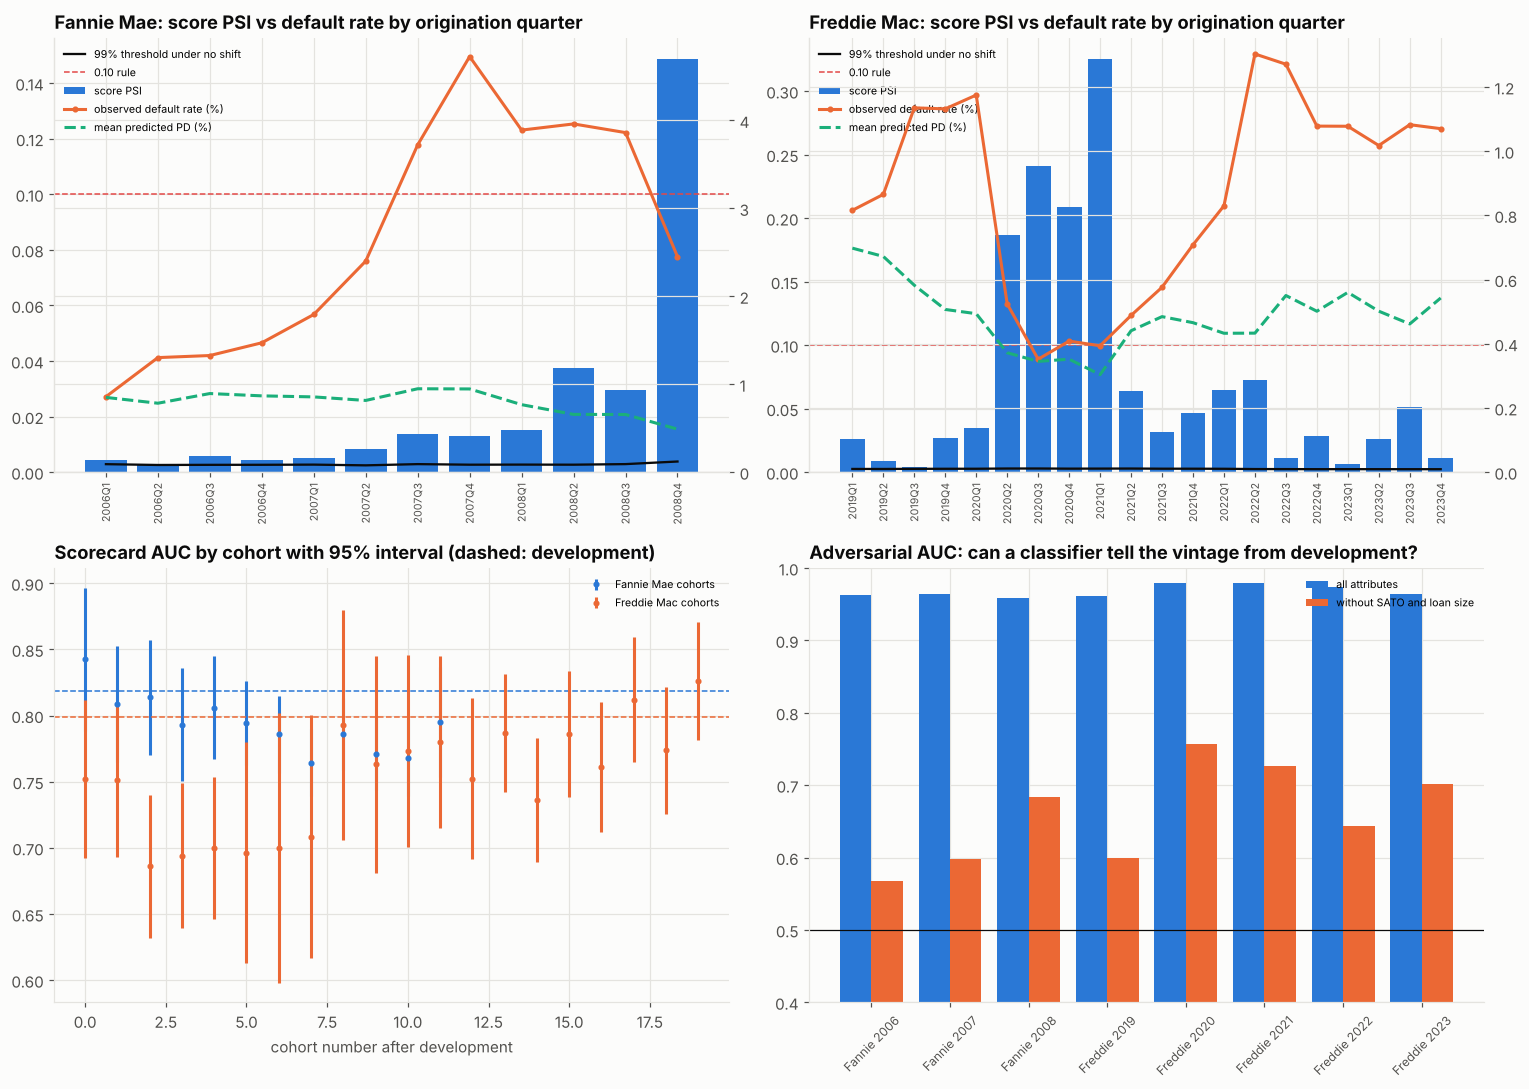

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for a, book in zip(ax[0], BOOKS):
    m = MON.loc[book]
    x = np.arange(len(m))
    a.bar(x, m["score PSI"], color=PALETTE[0], label="score PSI")
    a.plot(
        x,
        m["PSI threshold 99%"],
        color=INK,
        lw=1.5,
        label="99% threshold under no shift",
    )
    a.axhline(0.10, color=PALETTE[7], ls="--", lw=1, label="0.10 rule")
    a2 = a.twinx()
    a2.plot(
        x,
        m["default rate"] * 100,
        color=PALETTE[1],
        marker="o",
        ms=3,
        label="observed default rate (%)",
    )
    a2.plot(
        x,
        m["mean PD"] * 100,
        color=PALETTE[2],
        ls="--",
        label="mean predicted PD (%)",
    )
    a2.set_ylim(bottom=0)
    a.set_xticks(x)
    a.set_xticklabels(m.index, rotation=90, fontsize=7)
    a.set_title(f"{book}: score PSI vs default rate by origination quarter")
    h1, l1 = a.get_legend_handles_labels()
    h2, l2 = a2.get_legend_handles_labels()
    a.legend(h1 + h2, l1 + l2, fontsize=7, loc="upper left")
a = ax[1, 0]
for book, col in zip(BOOKS, PALETTE):
    m = MON.loc[book]
    a.errorbar(
        range(len(m)),
        m["AUC scorecard"],
        yerr=[
            m["AUC scorecard"] - m["AUC low"],
            m["AUC high"] - m["AUC scorecard"],
        ],
        fmt="o",
        ms=3,
        color=col,
        label=f"{book} cohorts",
    )
    a.axhline(DEV_AUC[book][0], color=col, ls="--", lw=1)
a.set_title("Scorecard AUC by cohort with 95% interval (dashed: development)")
a.set_xlabel("cohort number after development")
a.legend(fontsize=7)
a = ax[1, 1]
lab = [f"{b.split()[0]} {v}" for b, v in ADV.index]
xpos = np.arange(len(ADV))
a.bar(
    xpos - 0.2,
    ADV["adversarial AUC"],
    0.4,
    color=PALETTE[0],
    label="all attributes",
)
a.bar(
    xpos + 0.2,
    ADV["adversarial AUC without SATO and loan size"],
    0.4,
    color=PALETTE[1],
    label="without SATO and loan size",
)
a.axhline(0.5, color=INK, lw=0.8)
a.set_ylim(0.4, 1)
a.set_xticks(xpos)
a.set_xticklabels(lab, rotation=45, fontsize=8)
a.set_title(
    "Adversarial AUC: can a classifier tell the vintage from development?"
)
a.legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "01_model_monitoring")
plt.show()

In [13]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Attribute stability (CSI) by cohort, Freddie Mac",
        "Implied vs observed change in default rate (pp)",
        "Univariate AUC screen (leaky fields in red)",
        "Average AUC: scorecard, challenger and benchmarks",
    ),
)
c = CSI.loc["Freddie Mac"]
dash.add_trace(
    go.Heatmap(
        z=c.T.values,
        x=c.index,
        y=c.columns,
        colorscale="Blues",
        colorbar=dict(x=0.45, len=0.4, y=0.8),
    ),
    1,
    1,
)
for book in BOOKS:
    m = MON.loc[book]
    dev_dr = L.loc[DEV[book].index, "default"].mean()
    dash.add_trace(
        go.Scatter(
            x=m["implied default-rate shift"] * 100,
            y=(m["default rate"] - dev_dr) * 100,
            mode="markers",
            name=book,
            text=m.index,
        ),
        1,
        2,
    )
dash.add_trace(
    go.Bar(
        x=LEAK.index,
        y=LEAK["univariate AUC"],
        marker_color=[
            PALETTE[0] if k else PALETTE[7]
            for k in LEAK["known at origination"]
        ],
        name="univariate AUC",
    ),
    2,
    1,
)
for col in BENCH.columns:
    dash.add_trace(go.Bar(x=BENCH.index, y=BENCH[col], name=col), 2, 2)
dash.update_layout(
    height=950,
    width=1400,
    template="simple_white",
    barmode="group",
    title=(
        "Monitoring mortgage PD models: PSI, adversarial validation, drift"
        " detectors and leakage checks"
    ),
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

**Two episodes.**
- **Fannie Mae 2005–2008 vintages:** the share of loans defaulting within 18 months rose from 0.7% (2005) to 1.0%, 2.6% and 3.1%.
- **Freddie Mac 2018–2023 vintages:** default rates moved between 0.5% and 1.1%. The applicant mix swung instead: refinancings were 33% of loans in 2018, 70% in 2020 and 16% in 2023.

The scorecard developed on 2005 has an AUC of 0.82 (±0.03); the one developed on 2018, 0.80 (±0.03).

**2006–2008: the PSI never moved, the default rate quintupled.**
- **Stability:** from 2006Q1 to 2008Q3 the score PSI stayed between 0.003 and 0.04, well inside "stable". The change in score mix implied a change in the expected default rate of at most 0.12 points.
- **Calibration:** the default rate of each quarterly cohort rose from 0.9% to 4.7% (2007Q4), while the scorecard kept predicting 0.7–1.0%. The calibration z-score was already 6 in 2006Q2 and passed 40 in 2008.
- **Ranking:** discrimination held up (AUC 0.76–0.84), so the model kept ranking borrowers correctly while missing the level by a factor of five. This was a concept shift, house prices turning, and no population index can see it.

**2020–2021: the PSI exploded, the model was fine.** The refinancing boom pushed the score PSI to 0.19–0.33 in 2020Q2–2021Q1, above the "act" threshold of 0.25 at its peak. Yet the shift was toward better borrowers: the implied default-rate change was −0.3 points, the observed default rates (0.35–0.52%) were close to the predicted ones, and the calibration z-scores were below 2.5.

The real problem came later and quietly. The 2022Q2 cohort defaulted at 1.3% against a predicted 0.4% (z = 14) with a PSI of only 0.07.

**Statistical thresholds.** Under no shift, the 99% critical value of the PSI is 0.0025–0.004 for these cohorts of 7,000–12,000 loans. Nearly every cohort exceeds it, so the shifts are real, but most are immaterial.

The 0.10 rule corresponds to a monitoring sample of about 220 loans:

| Monitoring loans | 99% critical PSI |
|---|---|
| 250 | 0.087 |
| 1,000 | 0.022 |
| 10,000 | 0.003 |

A threshold should combine significance (is the shift real?) with materiality (does it change expected defaults or the ranking?). The implied default-rate shift is a simple materiality measure.

**Adversarial validation.**
- **With all attributes:** a classifier tells every later vintage from its development vintage with an AUC of 0.96–0.98. It does so almost entirely through two attributes that drift by construction: the spread at origination, whose level depends on the rate environment, and the loan amount, which grows with house prices.
- **Without those two:** the AUC is 0.57–0.68 for the 2006–2008 vintages, which look like 2005, and 0.60–0.76 for 2019–2023. The 2020 vintage stands out (0.76), separated by loan purpose.

Adversarial validation is a sensitive alarm, but it needs the same materiality filter as the PSI, and inflation-driven attributes should be expressed in real or relative terms before monitoring.

**Drift detectors and the label delay.**

| Detector | Fannie Mae: first alarm | Freddie Mac: first alarm |
|---|---|---|
| ADWIN on the score (at origination) | December 2006 | August 2019 |
| ADWIN on the calibration residual (18 months later) | January 2008 | May 2021 |
| DDM on defaults (18 months later) | June 2008 | December 2020 |

- **Score detector:** it reacts quickly, but only to population shifts, which in 2006 were small and in 2020 were benign.
- **Outcome detectors:** they found the 2006–2007 deterioration in 2008, after the worst vintages were already on the books. The 18-month label delay, not the detector, sets the speed.

Early warning needs leading outcomes, such as 30- and 60-day delinquencies at 6 months, or macro and collateral indicators, rather than more sensitive detectors on the final target.

**Leakage.** The univariate screen ranks *ever modified* (AUC 0.79) above FICO (0.74), and *months reported* at 0.64. Both are known only after origination. Adding them lifts the scorecard's cross-validated AUC from 0.79 to 0.90.

A check of each field's availability date, plus a screen for any field more predictive than the strongest known driver, catches this kind of leak.

Temporal leakage did not inflate performance here. Random cross-validation on 2018–2021 gave 0.75; training on 2018–2020 and testing on 2021–2023 gave 0.78. The later vintages were easier to rank, so the out-of-time test should still be the reference.

**Bin stability and parameter uncertainty.**
- **Bin reversals:** in later vintages up to nine adjacent WoE bins reverse their order, mostly in loan size, spread at origination and debt-to-income. FICO and CLTV bins stay almost perfectly ordered.
- **Unstable coefficients:** five of the thirteen 90% bootstrap intervals include zero (mortgage insurance, purpose, property type, first-time buyer, multi-unit). These are weak attributes that a parsimonious scorecard could drop.
- **Ranking:** across bootstrap refits, 40% of the next vintage's loans change score decile, but only 4% move by two deciles or more.

**Benchmarks.** Average AUC over the monitoring cohorts:

| Book | Scorecard | LightGBM | FICO only | FICO, CLTV, DTI |
|---|---|---|---|---|
| Fannie Mae | 0.794 | 0.788 | 0.770 | 0.787 |
| Freddie Mac | 0.752 | 0.737 | 0.711 | 0.733 |

The scorecard adds 2–4 points over FICO alone, but less than 1–2 points over a three-variable model. The LightGBM challenger, trained on one vintage, generalises no better than the scorecard.

**What this means for model monitoring.**
- **A PSI below 0.10 is neither necessary nor sufficient.** It missed the largest deterioration in the data and flagged a benign shift. Monitor calibration and discrimination by cohort with confidence intervals, and judge population shifts by their implied effect on expected defaults.
- **Size thresholds statistically.** For large portfolios a fixed 0.10 is far too lax; for small segments it is too strict.
- **Label delay:** use leading indicators (early delinquency, collateral values, macro conditions) to shorten the delay that outcome-based detectors cannot avoid.
- **Before deployment:** screen for leakage by availability date, check WoE bins for reversals across vintages, bootstrap the coefficients, and report the gain over a FICO-only and a three-variable benchmark.

**Limitations.**
- **Data:** samples of 50,000 loans per vintage, from two lenders and two periods. Default rates of 0.5–1% leave 50–120 defaults per quarterly cohort, so cohort AUCs carry intervals of ±0.05–0.10.
- **Default definition:** the 18-month horizon and the forbearance rule are choices; a 24-month horizon would raise default rates and delay labels further.
- **Detectors:** ADWIN and DDM are run with standard settings (δ = 0.002, three standard deviations) and restart after each alarm; other settings change the alarm dates.
- **Selection:** all models are trained on approved, purchased loans, so the effect of shifting approval policy on the population cannot be separated from the applicant pool.

In [14]:
MON.to_csv(OUT_DIR / "monitoring_by_cohort.csv")
CSI.to_csv(OUT_DIR / "characteristic_stability_by_cohort.csv")
THRESH.to_csv(OUT_DIR / "psi_thresholds_by_sample_size.csv", index=False)
ADV.to_csv(OUT_DIR / "adversarial_validation.csv")
DETECT.to_csv(OUT_DIR / "drift_detector_alarms.csv")
LEAK.to_csv(OUT_DIR / "leakage_screen.csv")
LEAK_CV.to_csv(OUT_DIR / "leakage_cross_validation.csv")
STAB.to_csv(OUT_DIR / "woe_bin_stability.csv", index=False)
UNC.to_csv(OUT_DIR / "bootstrap_coefficients.csv")
BENCH.to_csv(OUT_DIR / "benchmark_auc.csv")
IV.to_csv(OUT_DIR / "information_value.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_model_monitoring.png, adversarial_validation.csv, benchmark_auc.csv, bootstrap_coefficients.csv, characteristic_stability_by_cohort.csv, dashboard.html, dashboard.png, drift_detector_alarms.csv, information_value.csv, leakage_cross_validation.csv, leakage_screen.csv, monitoring_by_cohort.csv, psi_thresholds_by_sample_size.csv, woe_bin_stability.csv


## References

### Credit scoring and model monitoring

- Siddiqi, N. (2017). *Intelligent credit scoring: Building and implementing better credit risk scorecards* (2nd ed.). Wiley. https://doi.org/10.1002/9781119282396
- Yurdakul, B., & Naranjo, J. (2020). Statistical properties of the population stability index. *The Journal of Risk Model Validation*. https://doi.org/10.21314/JRMV.2020.227
- Hanley, J. A., & McNeil, B. J. (1982). The meaning and use of the area under a receiver operating characteristic (ROC) curve. *Radiology, 143*(1), 29–36. https://doi.org/10.1148/radiology.143.1.7063747
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), 1–21. https://doi.org/10.1145/2382577.2382579
- Basel Committee on Banking Supervision. (2005). *Studies on the validation of internal rating systems* (Working Paper No. 14). Bank for International Settlements. https://www.bis.org/publ/bcbs_wp14.htm

### Drift detection and machine learning

- Gama, J., Medas, P., Castillo, G., & Rodrigues, P. (2004). Learning with drift detection. In *Advances in Artificial Intelligence – SBIA 2004* (pp. 286–295). Springer. https://doi.org/10.1007/978-3-540-28645-5_29
- Bifet, A., & Gavaldà, R. (2007). Learning from time-changing data with adaptive windowing. In *Proceedings of the 2007 SIAM International Conference on Data Mining* (pp. 443–448). https://doi.org/10.1137/1.9781611972771.42
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html

### Data

- Fannie Mae. (2026). *Single-Family Loan Performance Data* [Data set]. https://capitalmarkets.fanniemae.com/credit-risk-transfer/single-family-credit-risk-transfer/fannie-mae-single-family-loan-performance-data
- Freddie Mac. (2026). *Single-Family Loan-Level Dataset* [Data set]. https://www.freddiemac.com/research/datasets/sf-loanlevel-dataset
- Freddie Mac. (2026). *30-year fixed rate mortgage average in the United States* [Data set]. Federal Reserve Bank of St. Louis (FRED). https://fred.stlouisfed.org/series/MORTGAGE30US